In [2]:
import re
import nltk
import string
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense


nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

text = """Technology fascinates me because it transforms the way people learn, communicate, and solve problems.
Artificial intelligence can help students understand difficult concepts and explore new ideas.
I enjoy discovering how simple lines of code can create useful applications.
Technology also connects people across the world and makes information easier to access.
However, I believe it is important to use technology responsibly and maintain a balance between digital and real-world experiences."""

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


# Question 1

In [3]:
# 1.lowercase and no punctuation
cleaned_text = re.sub(r'[^\w\s]', '', text.lower())
print("cleaned text:\n", cleaned_text)

# 2.tokenize
sentences = sent_tokenize(text)
words = word_tokenize(cleaned_text)

print("\nsentences:")
print(sentences)

print("\nwords:")
print(words)

# 3.comparing split() and word_tokenize()
split_words = cleaned_text.split()
nltk_words = word_tokenize(cleaned_text)

print("\nusing split():")
print(split_words)

print("\nusing word_tokenize():")
print(nltk_words)

print(split_words == nltk_words)

# 4.removing stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [
    word for word in nltk_words
    if word not in stop_words and word.isalpha()
]

print("\n after stopword removal:")
print(filtered_words)

# 5. word frequency distribution
frequency = FreqDist(filtered_words)

print("\nword frequency distribution:")
for word, count in frequency.most_common():
    print(f"{word}: {count}")


cleaned text:
 technology fascinates me because it transforms the way people learn communicate and solve problems
artificial intelligence can help students understand difficult concepts and explore new ideas
i enjoy discovering how simple lines of code can create useful applications
technology also connects people across the world and makes information easier to access
however i believe it is important to use technology responsibly and maintain a balance between digital and realworld experiences

sentences:
['Technology fascinates me because it transforms the way people learn, communicate, and solve problems.', 'Artificial intelligence can help students understand difficult concepts and explore new ideas.', 'I enjoy discovering how simple lines of code can create useful applications.', 'Technology also connects people across the world and makes information easier to access.', 'However, I believe it is important to use technology responsibly and maintain a balance between digital and re

# Question 2

In [4]:
# 1.
words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("1. Alphabetic Words:")
print(words)

# 2.
stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]
print("\n2. Words after Stopword Removal:")
print(filtered_words)

# 3.
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in filtered_words]
print("\n3. Stemmed Words:")
print(stemmed_words)

# 4.
lemmatizer = WordNetLemmatizer()
lemmatized_words = [
    lemmatizer.lemmatize(word) for word in filtered_words
]
print("\n4. Lemmatized Words:")
print(lemmatized_words)

# 5.
print("\n5. Comparison:")
for original, stem, lemma in zip(
    filtered_words, stemmed_words, lemmatized_words
):
    print(f"{original:15} -> Stem: {stem:12} Lemma: {lemma}")


1. Alphabetic Words:
['technology', 'fascinates', 'me', 'because', 'it', 'transforms', 'the', 'way', 'people', 'learn', 'communicate', 'and', 'solve', 'problems', 'artificial', 'intelligence', 'can', 'help', 'students', 'understand', 'difficult', 'concepts', 'and', 'explore', 'new', 'ideas', 'i', 'enjoy', 'discovering', 'how', 'simple', 'lines', 'of', 'code', 'can', 'create', 'useful', 'applications', 'technology', 'also', 'connects', 'people', 'across', 'the', 'world', 'and', 'makes', 'information', 'easier', 'to', 'access', 'however', 'i', 'believe', 'it', 'is', 'important', 'to', 'use', 'technology', 'responsibly', 'and', 'maintain', 'a', 'balance', 'between', 'digital', 'and', 'real', 'world', 'experiences']

2. Words after Stopword Removal:
['technology', 'fascinates', 'transforms', 'way', 'people', 'learn', 'communicate', 'solve', 'problems', 'artificial', 'intelligence', 'help', 'students', 'understand', 'difficult', 'concepts', 'explore', 'new', 'ideas', 'enjoy', 'discovering',

# Question 3

In [5]:
# Three short texts
texts = [
    "Artificial intelligence helps students learn faster and solve problems.",
    "The new smartphone offers excellent battery life and a powerful camera.",
    "Healthy food and regular exercise improve fitness and mental health."
]

# 1.
count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)

print("1. bag of words:")
print("vocab:", count_vectorizer.get_feature_names_out())
print(bow_matrix.toarray())

# 2.
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

print("\n2. tf-idf")
print("vocab:", tfidf_vectorizer.get_feature_names_out())
print(tfidf_matrix.toarray().round(3))

# 3.
feature_names = tfidf_vectorizer.get_feature_names_out()

print("\n3. top 3")

for i, text in enumerate(texts):
    scores = tfidf_matrix[i].toarray().flatten()
    top_indices = scores.argsort()[::-1][:3]

    keywords = [
        (feature_names[index], round(scores[index], 3))
        for index in top_indices
    ]

    print(f"\ntext {i + 1}: {text}")
    print("top 3 keywords:", keywords)


1. bag of words:
vocab: ['and' 'artificial' 'battery' 'camera' 'excellent' 'exercise' 'faster'
 'fitness' 'food' 'health' 'healthy' 'helps' 'improve' 'intelligence'
 'learn' 'life' 'mental' 'new' 'offers' 'powerful' 'problems' 'regular'
 'smartphone' 'solve' 'students' 'the']
[[1 1 0 0 0 0 1 0 0 0 0 1 0 1 1 0 0 0 0 0 1 0 0 1 1 0]
 [1 0 1 1 1 0 0 0 0 0 0 0 0 0 0 1 0 1 1 1 0 0 1 0 0 1]
 [2 0 0 0 0 1 0 1 1 1 1 0 1 0 0 0 1 0 0 0 0 1 0 0 0 0]]

2. tf-idf
vocab: ['and' 'artificial' 'battery' 'camera' 'excellent' 'exercise' 'faster'
 'fitness' 'food' 'health' 'healthy' 'helps' 'improve' 'intelligence'
 'learn' 'life' 'mental' 'new' 'offers' 'powerful' 'problems' 'regular'
 'smartphone' 'solve' 'students' 'the']
[[0.204 0.346 0.    0.    0.    0.    0.346 0.    0.    0.    0.    0.346
  0.    0.346 0.346 0.    0.    0.    0.    0.    0.346 0.    0.    0.346
  0.346 0.   ]
 [0.193 0.    0.327 0.327 0.327 0.    0.    0.    0.    0.    0.    0.
  0.    0.    0.    0.327 0.    0.327 0.327 0.327 0.

# Question 4

In [6]:
text1 = """
Artificial intelligence enables computers to learn from data.
AI systems can recognize patterns and solve complex problems.
Machine learning improves predictions using previous experiences.
AI is widely used in healthcare, education, and automation.
It helps people make faster and smarter decisions.
"""

text2 = """
Blockchain is a decentralized digital ledger technology.
It stores transactions securely across multiple computers.
Blockchain uses cryptography to protect digital records.
It is widely used in cryptocurrency and secure transactions.
This technology improves transparency and trust.
"""

# 1.
stop_words = set(stopwords.words('english'))

def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in stop_words]
    return tokens

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("1. PREPROCESSED TOKENS")
print("AI:", tokens1)
print("Blockchain:", tokens2)

# 2(a).
set1 = set(tokens1)
set2 = set(tokens2)

intersection = set1.intersection(set2)
union = set1.union(set2)

jaccard = len(intersection) / len(union) if union else 0

print("\n2(a). JACCARD SIMILARITY")
print("Common words:", intersection)
print("Jaccard Similarity:", round(jaccard, 4))

# 2(b).
documents = [
    ' '.join(tokens1),
    ' '.join(tokens2)
]

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(documents)

cosine = cosine_similarity(
    tfidf_matrix[0:1],
    tfidf_matrix[1:2]
)[0][0]

print("\n2(b). COSINE SIMILARITY")
print("Cosine Similarity:", round(cosine, 4))

# 3.
print("\n3. ANALYSIS")
print("Jaccard Similarity measures shared unique words.")
print("Cosine Similarity compares TF-IDF weighted word vectors.")

if jaccard < 0.3 and cosine < 0.3:
    print("Both metrics indicate low textual similarity.")
elif cosine > jaccard:
    print("Cosine similarity indicates relatively greater similarity.")
else:
    print("Jaccard similarity indicates relatively greater overlap.")


1. PREPROCESSED TOKENS
AI: ['artificial', 'intelligence', 'enables', 'computers', 'learn', 'data', 'ai', 'systems', 'recognize', 'patterns', 'solve', 'complex', 'problems', 'machine', 'learning', 'improves', 'predictions', 'using', 'previous', 'experiences', 'ai', 'widely', 'used', 'healthcare', 'education', 'automation', 'helps', 'people', 'make', 'faster', 'smarter', 'decisions']
Blockchain: ['blockchain', 'decentralized', 'digital', 'ledger', 'technology', 'stores', 'transactions', 'securely', 'across', 'multiple', 'computers', 'blockchain', 'uses', 'cryptography', 'protect', 'digital', 'records', 'widely', 'used', 'cryptocurrency', 'secure', 'transactions', 'technology', 'improves', 'transparency', 'trust']

2(a). JACCARD SIMILARITY
Common words: {'improves', 'widely', 'used', 'computers'}
Jaccard Similarity: 0.0816

2(b). COSINE SIMILARITY
Cosine Similarity: 0.0632

3. ANALYSIS
Jaccard Similarity measures shared unique words.
Cosine Similarity compares TF-IDF weighted word vectors

# Question 5

Polarity:  0.6875
Subjectivity:  0.75


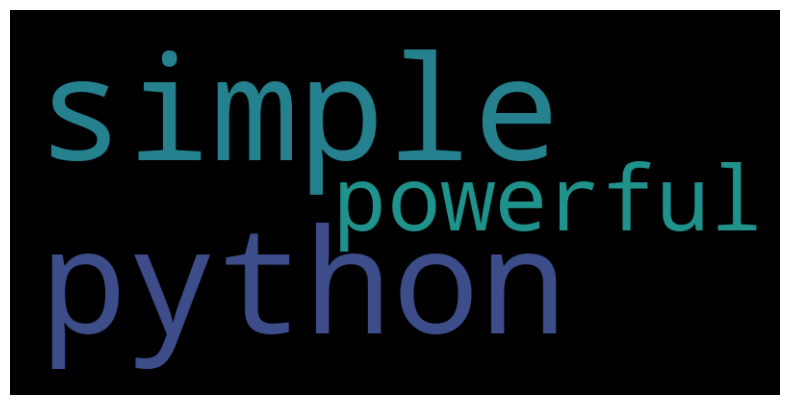

In [7]:
review = "the service was excellent and the staff was friendly"

blob = TextBlob(review)
# 1.
print("Polarity: ", blob.sentiment.polarity)
print("Subjectivity: ", blob.sentiment.subjectivity)

text = "python is simple and powerful"
wordcloud = WordCloud(width=800, height=400).generate(text)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()

# Question 6

In [9]:
text = """
Technology changes the world and helps people learn new things.
Artificial intelligence allows computers to solve problems and recognize patterns.
Students use technology to explore ideas and improve their knowledge.
Machine learning helps systems learn from data and make predictions.
Computers process information quickly and support scientific research.
Technology connects people and makes communication easier.
Developers create applications to solve everyday problems.
The future of technology depends on creativity and responsible innovation.
Artificial intelligence and machine learning continue to improve modern life.
People can use technology to build a better future.
"""

# 2.
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1
print("Vocabulary Size:", total_words)
print("Word Index:", tokenizer.word_index)

# 3.
input_sequences = []

for line in text.lower().split('.'):
    line = line.strip()
    if line:
        token_list = tokenizer.texts_to_sequences([line])[0]

        for i in range(1, len(token_list)):
            n_gram_sequence = token_list[:i + 1]
            input_sequences.append(n_gram_sequence)

max_sequence_len = max(len(seq) for seq in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

X = input_sequences[:, :-1]
y = input_sequences[:, -1]

y = tf.keras.utils.to_categorical(y, num_classes=total_words)

print("\nInput Shape:", X.shape)
print("Output Shape:", y.shape)

# 4.lstm model
model = Sequential([
    Embedding(total_words, 32, input_length=max_sequence_len - 1),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

# 5. training the model
model.fit(X, y, epochs=200, verbose=0)

# 6.
def generate_text(seed_text, next_words=10):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding='pre'
        )

        predicted_probs = model.predict(token_list, verbose=0)[0]
        predicted_word_index = int(np.argmax(predicted_probs))

        output_word = tokenizer.index_word.get(
            predicted_word_index, ''
        )

        if not output_word:
            break

        seed_text += " " + output_word

    return seed_text

print("\nGenerated Text:")
print(generate_text("technology", 8))
print(generate_text("artificial", 8))
print(generate_text("people", 8))


Vocabulary Size: 62
Word Index: {'and': 1, 'technology': 2, 'to': 3, 'people': 4, 'the': 5, 'helps': 6, 'learn': 7, 'artificial': 8, 'intelligence': 9, 'computers': 10, 'solve': 11, 'problems': 12, 'use': 13, 'improve': 14, 'machine': 15, 'learning': 16, 'future': 17, 'changes': 18, 'world': 19, 'new': 20, 'things': 21, 'allows': 22, 'recognize': 23, 'patterns': 24, 'students': 25, 'explore': 26, 'ideas': 27, 'their': 28, 'knowledge': 29, 'systems': 30, 'from': 31, 'data': 32, 'make': 33, 'predictions': 34, 'process': 35, 'information': 36, 'quickly': 37, 'support': 38, 'scientific': 39, 'research': 40, 'connects': 41, 'makes': 42, 'communication': 43, 'easier': 44, 'developers': 45, 'create': 46, 'applications': 47, 'everyday': 48, 'of': 49, 'depends': 50, 'on': 51, 'creativity': 52, 'responsible': 53, 'innovation': 54, 'continue': 55, 'modern': 56, 'life': 57, 'can': 58, 'build': 59, 'a': 60, 'better': 61}

Input Shape: (81, 9)
Output Shape: (81, 62)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Generated Text:
technology changes the world and helps people learn new
artificial intelligence and machine learning continue to improve modern
people use technology to to build a better future
